# Titanic analysis

In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## data extraction


In [30]:
df = sns.load_dataset("titanic")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [6]:
df["age"].isna()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888     True
889    False
890    False
Name: age, Length: 891, dtype: bool

In [7]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
886     True
887    False
888    False
889    False
890    False
Length: 891, dtype: bool

In [36]:
df["survived"].value_counts()

survived
0    461
1    323
Name: count, dtype: int64

In [37]:
df["fare"].describe()

count    784.000000
mean      34.711740
std       52.160151
min        0.000000
25%        8.050000
50%       15.900000
75%       34.109350
max      512.329200
Name: fare, dtype: float64

## data cleaning


In [31]:
df = df.drop_duplicates()
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [32]:
df = df.drop(columns='alive')
df = df.drop(columns='alone')
df = df.drop(columns='embarked')
df = df.drop(columns='adult_male')
df = df.drop(columns='pclass')

In [38]:
df

,survived,sex,age,sibsp,parch,fare,class,who,deck,embark_town
0,0,male,22.0,1,0,7.2500,Third,man,NaN,Southampton
1,1,female,38.0,1,0,71.2833,First,woman,C,Cherbourg
2,1,female,26.0,0,0,7.9250,Third,woman,NaN,Southampton
3,1,female,35.0,1,0,53.1000,First,woman,C,Southampton
4,0,male,35.0,0,0,8.0500,Third,man,NaN,Southampton
...,...,...,...,...,...,...,...,...,...,...
885,0,female,39.0,0,5,29.1250,Third,woman,NaN,Queenstown
887,1,female,19.0,0,0,30.0000,First,woman,B,Southampton
888,0,female,NaN,1,2,23.4500,Third,woman,NaN,Southampton
889,1,male,26.0,0,0,30.0000,First,man,C,Cherbourg


In [35]:
df.info()


<class 'pandas.DataFrame'>
Index: 784 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     784 non-null    int64   
 1   sex          784 non-null    str     
 2   age          678 non-null    float64 
 3   sibsp        784 non-null    int64   
 4   parch        784 non-null    int64   
 5   fare         784 non-null    float64 
 6   class        784 non-null    category
 7   who          784 non-null    str     
 8   deck         202 non-null    category
 9   embark_town  782 non-null    str     
dtypes: category(2), float64(2), int64(3), str(3)
memory usage: 57.1 KB


In [41]:
df["survived"] = df["survived"].astype(np.uint8)
df["sibsp"] = df["sibsp"].astype(np.uint8)
df["parch"] = df["parch"].astype(np.uint8)
df["parch"] = df["parch"].astype(np.uint8)
df["fare"] = df["fare"].astype(np.float32)

In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 784 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     784 non-null    uint8   
 1   sex          784 non-null    str     
 2   age          678 non-null    float64 
 3   sibsp        784 non-null    uint8   
 4   parch        784 non-null    uint8   
 5   fare         784 non-null    float32 
 6   class        784 non-null    category
 7   who          784 non-null    str     
 8   deck         202 non-null    category
 9   embark_town  782 non-null    str     
dtypes: category(2), float32(1), float64(1), str(3), uint8(3)
memory usage: 38.0 KB


## visualization


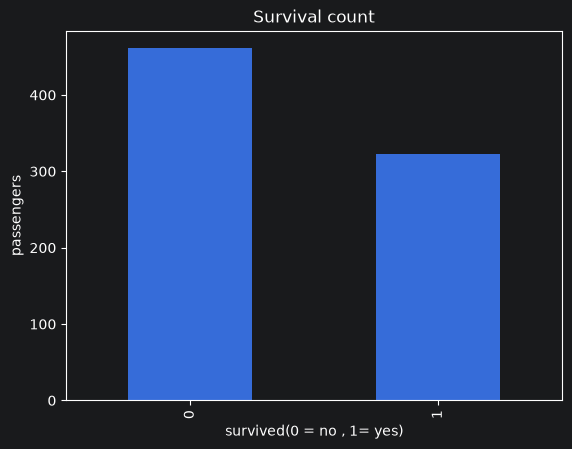

In [45]:
df['survived'].value_counts().plot(kind='bar')
plt.title('Survival count')
plt.xlabel('survived(0 = no , 1= yes)')
plt.ylabel('passengers')
plt.show()

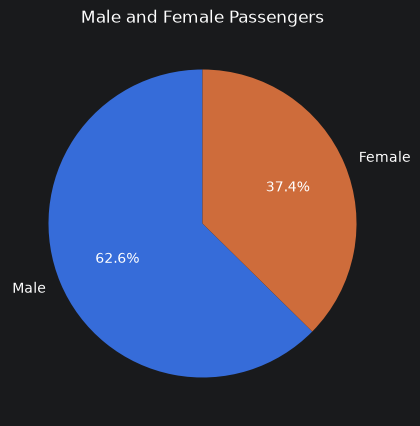

In [47]:
sex_counts = df["sex"].value_counts()

plt.figure(figsize=(10,5))

plt.pie(
    sex_counts,
    labels=["Male", "Female"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Male and Female Passengers")
plt.show()